# Сверка платежей с PSP: учёт против отчётов платёжных систем

Pet-проект на синтетических данных. Модель повторяет ежедневную работу платёжной команды iGaming-оператора: депозиты и выводы игроков через три PSP за сентябрь 2026.

Что делаю в ноутбуке:
1. Проверяю качество данных до сверки: дубли, пропуски.
2. Свожу внутренний учёт с отчётами PSP SQL-запросом и нахожу расхождения по статусам, суммам и комиссиям.
3. Считаю match rate по PSP и по дням, ищу аномальные дни.
4. Контролирую балансы на счетах PSP: ожидание против факта.
5. Собираю отчёт для трейдеров: оборот, отказы, эффективная комиссия.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..')
DATA, CHARTS = ROOT / 'data', ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)

COLORS = {'PSP Alfa': '#2F6FDE', 'PSP Beta': '#8B5CF6', 'PSP Gamma': '#F08A24'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#EEF0F3', 'axes.axisbelow': True,
                     'figure.dpi': 110})

ledger = pd.read_csv(DATA / 'ledger.csv')
psp_report = pd.read_csv(DATA / 'psp_report.csv')
balances = pd.read_csv(DATA / 'balances.csv')
payments = pd.read_csv(DATA / 'payments_weekly.csv')
print(f'Учёт: {len(ledger):,} строк · отчёты PSP: {len(psp_report):,} строк'.replace(',', ' '))

Учёт: 11 727 строк · отчёты PSP: 11 728 строк


## 1. Качество данных до сверки

In [2]:
checks = pd.DataFrame({
    'дубли txn_id': [ledger.txn_id.duplicated().sum(), psp_report.txn_id.duplicated().sum()],
    'пустые значения': [ledger.isna().sum().sum(), psp_report.isna().sum().sum()],
    'отрицательные суммы': [(ledger.amount_eur < 0).sum(), (psp_report.amount_eur < 0).sum()],
}, index=['ledger', 'psp_report'])
checks

,дубли txn_id,пустые значения,отрицательные суммы
ledger,0,0,0
psp_report,0,0,0


## 2. Сверка SQL-запросом
Запрос лежит в `sql/reconciliation.sql`: FULL OUTER JOIN по `txn_id` и классификация каждой транзакции.

In [3]:
con = sqlite3.connect(':memory:')
for name, df in {'ledger': ledger, 'psp_report': psp_report,
                 'balances': balances, 'payments_weekly': payments}.items():
    df.to_sql(name, con, index=False)

recon = pd.read_sql((ROOT / 'sql' / 'reconciliation.sql').read_text(encoding='utf-8'), con)
recon.to_sql('recon_result', con, index=False)
breaks = recon[recon.recon_result != 'matched']

total, n_breaks = len(recon), len(breaks)
print(f'Транзакций: {total} · расхождений: {n_breaks} · match rate: {100 * (1 - n_breaks / total):.2f}%')

Транзакций: 11738 · расхождений: 53 · match rate: 99.55%


In [4]:
by_psp = (recon.assign(is_break=recon.recon_result != 'matched')
          .groupby('psp').agg(transactions=('txn_id', 'size'), breaks=('is_break', 'sum')))
by_psp['match_rate_pct'] = (100 * (1 - by_psp.breaks / by_psp.transactions)).round(2)
by_psp

,transactions,breaks,match_rate_pct
psp,,,
PSP Alfa,5699,8,99.86
PSP Beta,3866,7,99.82
PSP Gamma,2173,38,98.25


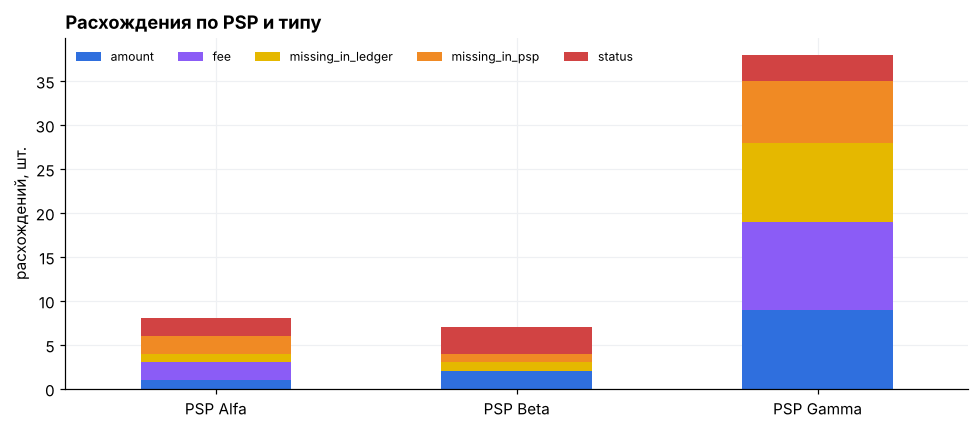

In [5]:
pivot = breaks.pivot_table(index='psp', columns='recon_result', values='txn_id', aggfunc='count', fill_value=0)
ax = pivot.plot(kind='bar', stacked=True, figsize=(9, 4), rot=0,
                color=['#2F6FDE', '#8B5CF6', '#E5B800', '#F08A24', '#D14343'][:pivot.shape[1]])
ax.set_title('Расхождения по PSP и типу', loc='left', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('расхождений, шт.'); ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(CHARTS / 'breaks_by_psp.png'); plt.show()

### Match rate по дням
Ищу дни, когда доля сверенных транзакций у PSP падает ниже 99%.

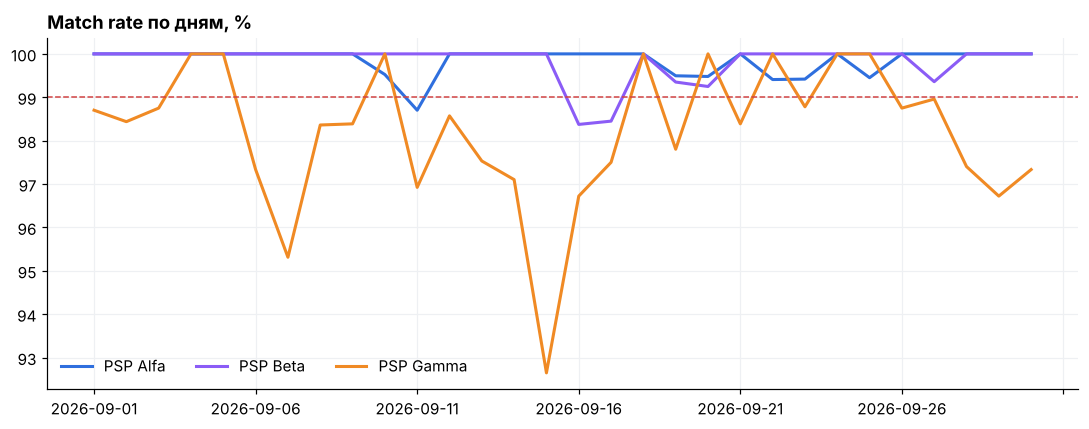

,txn_date,psp,match_rate_pct
2,2026-09-01,PSP Gamma,98.70
5,2026-09-02,PSP Gamma,98.44
8,2026-09-03,PSP Gamma,98.75
17,2026-09-06,PSP Gamma,97.33
20,2026-09-07,PSP Gamma,95.31
23,2026-09-08,PSP Gamma,98.36
26,2026-09-09,PSP Gamma,98.39
30,2026-09-11,PSP Alfa,98.70
32,2026-09-11,PSP Gamma,96.92
35,2026-09-12,PSP Gamma,98.57


In [6]:
daily = (recon.assign(ok=recon.recon_result == 'matched')
         .groupby(['txn_date', 'psp']).ok.mean().mul(100).unstack())
ax = daily.plot(figsize=(10, 4), color=[COLORS[c] for c in daily.columns], lw=2)
ax.axhline(99, color='#D14343', ls='--', lw=1)
ax.set_title('Match rate по дням, %', loc='left', fontweight='bold')
ax.set_xlabel(''); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.savefig(CHARTS / 'match_rate_daily.png'); plt.show()

low = daily.stack().round(2).rename('match_rate_pct').reset_index()
low[low.match_rate_pct < 99]

**Вывод.** PSP Gamma даёт большую часть расхождений, хотя проводит меньше всего транзакций, и регулярно опускается ниже 99%. Пик 14–17 сентября: стоит проверить у провайдера, не менялись ли тарифы или формат выгрузки.

Журнал открытых расхождений для разбора:

In [7]:
breaks.sort_values(['txn_date', 'psp'])[['txn_date', 'psp', 'txn_id', 'recon_result', 'break_amount_eur']].tail(10)

,txn_date,psp,txn_id,recon_result,break_amount_eur
9319,2026-09-25,PSP Alfa,ALF-0925-0000,missing_in_psp,197.22
10046,2026-09-26,PSP Gamma,GAM-0926-0000,amount,15.34
10358,2026-09-27,PSP Beta,BET-0927-0000,amount,27.61
11736,2026-09-27,PSP Gamma,GAM-0927-0000,missing_in_ledger,167.81
10928,2026-09-28,PSP Gamma,GAM-0928-0000,fee,3.25
10929,2026-09-28,PSP Gamma,GAM-0928-0001,amount,16.66
11286,2026-09-29,PSP Gamma,GAM-0929-0000,fee,0.72
11287,2026-09-29,PSP Gamma,GAM-0929-0001,status,153.67
11652,2026-09-30,PSP Gamma,GAM-0930-0000,fee,11.78
11653,2026-09-30,PSP Gamma,GAM-0930-0001,status,182.87


## 3. Контроль балансов на PSP
Дельта = фактический баланс из выписки PSP − ожидаемый по учёту. Порог эскалации: 500 € по модулю.

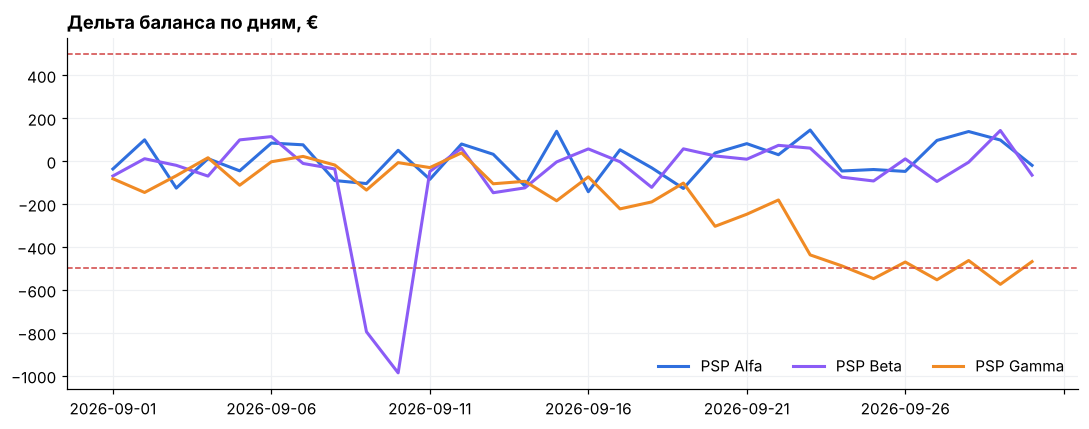

,balance_date,psp,delta_eur
38,2026-09-09,PSP Beta,-794.72
39,2026-09-10,PSP Beta,-986.36
84,2026-09-25,PSP Gamma,-547.48
86,2026-09-27,PSP Gamma,-552.62
88,2026-09-29,PSP Gamma,-573.79


In [8]:
balances['delta_eur'] = (balances.actual_balance_eur - balances.expected_balance_eur).round(2)
delta = balances.pivot(index='balance_date', columns='psp', values='delta_eur')
ax = delta.plot(figsize=(10, 4), color=[COLORS[c] for c in delta.columns], lw=2)
for y in (500, -500):
    ax.axhline(y, color='#D14343', ls='--', lw=1)
ax.set_title('Дельта баланса по дням, €', loc='left', fontweight='bold')
ax.set_xlabel(''); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.savefig(CHARTS / 'balance_delta.png'); plt.show()

balances[balances.delta_eur.abs() > 500][['balance_date', 'psp', 'delta_eur']]

**Вывод.** У PSP Beta разовый провал 9–10 сентября, на следующий день дельта вернулась к норме: похоже на задержку зачисления. У PSP Gamma с 14 сентября дельта стабильно уходит в минус: это систематическая недоплата, по времени совпадающая со всплеском расхождений по комиссиям.

## 4. Отчёт для трейдеров

In [9]:
report = pd.read_sql('''
    SELECT psp,
           ROUND(100.0 * SUM(successful) / SUM(transactions), 1) AS success_rate_pct,
           ROUND(SUM(volume_eur), 0)                             AS volume_eur,
           ROUND(SUM(fee_eur), 0)                                AS fee_eur,
           ROUND(100.0 * SUM(fee_eur) / SUM(volume_eur), 2)      AS effective_fee_pct
    FROM payments_weekly GROUP BY psp ORDER BY effective_fee_pct''', con)
report

,psp,success_rate_pct,volume_eur,fee_eur,effective_fee_pct
0,PSP Alfa,91.9,630810.0,11789.0,1.87
1,PSP Beta,86.5,390274.0,9157.0,2.35
2,PSP Gamma,80.2,220172.0,6593.0,2.99


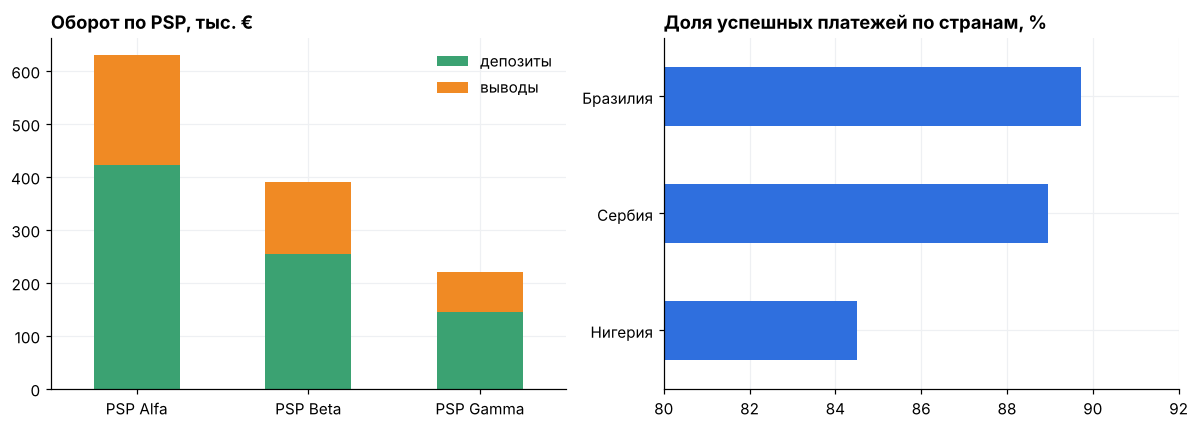

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
vol = payments.pivot_table(index='psp', columns='type', values='volume_eur', aggfunc='sum') / 1000
vol[['deposit', 'withdrawal']].plot(kind='bar', stacked=True, ax=axes[0], rot=0, color=['#3BA272', '#F08A24'])
axes[0].set_title('Оборот по PSP, тыс. €', loc='left', fontweight='bold'); axes[0].set_xlabel('')
axes[0].legend(['депозиты', 'выводы'], frameon=False)

by_country = payments.groupby('country')[['successful', 'transactions']].sum()
(100 * by_country.successful / by_country.transactions).sort_values().plot(kind='barh', ax=axes[1], color='#2F6FDE')
axes[1].set_title('Доля успешных платежей по странам, %', loc='left', fontweight='bold')
axes[1].set_xlim(80, 92); axes[1].set_ylabel('')
plt.tight_layout(); plt.savefig(CHARTS / 'payments_report.png'); plt.show()

**Выводы для стейкхолдеров**
- PSP Alfa — самый дешёвый и надёжный провайдер: больше всего оборота и самая низкая эффективная комиссия.
- PSP Gamma почти в 1,6 раза дороже Alfa и теряет каждую пятую транзакцию: стоит пересмотреть долю трафика или условия договора.
- В Нигерии самая низкая доля успешных платежей: отдельно разобрать причины отказов.